<a href="https://colab.research.google.com/github/Uriels28/Hands-on-3-Polynomial-Regression/blob/main/tutorial_regresion_polinomial_basado_en_six_sigma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión polinomial con Python y Scikit-learn
**Tutorial paso a paso para Google Colab o Jupyter**

## Objetivo
Implementar una regresión polinomial de grado 5, ajustar una curva a los datos y evaluar el ajuste mediante el coeficiente de determinación \(R^2\) y el análisis de residuos.

**Base teórica:** el contenido teórico de este notebook se limita a los conceptos explicados en [Regression — Six Sigma Material](https://www.six-sigma-material.com/Regression.html). La página presenta ejemplos lineales, cuadráticos y cúbicos; para cumplir la consigna de usar un grado mayor que 3, el código de este tutorial ajusta un polinomio de grado 5.

## 1. Fundamentos teóricos: método de mínimos cuadrados

La regresión permite estimar la relación entre una variable de entrada \(X\) (predictora) y una variable de respuesta \(Y\). La ecuación de regresión describe esa relación.

Un **residuo** es la diferencia entre el valor observado y el valor predicho:

\[
e_i = y_i - \hat{y}_i
\]

El **método de mínimos cuadrados** determina la curva que minimiza la suma de los cuadrados de los residuos:

\[
SS_{error}=\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
\]

La página de referencia explica que los residuos deben revisarse para evaluar si el modelo es aplicable.

## 2. Modelo matemático

Para una regresión polinomial de grado 5, la ecuación es:

\[
\hat{y}=\beta_0+\beta_1x+\beta_2x^2+\beta_3x^3+\beta_4x^4+\beta_5x^5
\]

Los coeficientes \(eta_0,\ldots,eta_5\) se estiman a partir de los datos mediante mínimos cuadrados.

La página de referencia muestra un ejemplo cúbico para estimar la eficiencia de una máquina según el tamaño del lote. Como la práctica pide un grado mayor que 3, en este notebook se utiliza grado 5.

## 3. Etapa del pipeline: importar las bibliotecas

Se importan las herramientas necesarias para organizar datos, crear gráficas, ajustar el polinomio y calcular \(R^2\).

In [9]:
import numpy as np  # Permite generar y trabajar con valores numéricos.
import pandas as pd  # Permite organizar los datos en una tabla.
import matplotlib.pyplot as plt  # Permite crear gráficas.
from sklearn.model_selection import train_test_split  # Divide los datos para entrenar y evaluar.
from sklearn.pipeline import Pipeline  # Encadena la transformación y el ajuste del modelo.
from sklearn.preprocessing import PolynomialFeatures  # Crea las potencias de x hasta el grado indicado.
from sklearn.linear_model import LinearRegression  # Ajusta los coeficientes usando mínimos cuadrados.
from sklearn.metrics import r2_score  # Calcula el coeficiente de determinación R².

## 4. Recolección de datos

La página utiliza como ejemplo el tamaño del lote (X) y la eficiencia de la máquina (Y), con valores de X entre 25 y 115. No proporciona en el texto una tabla completa de observaciones para descargar. Por eso, para demostrar el funcionamiento del código se generan datos simulados con una relación curva y ruido. Estos datos simulados son únicamente para ejecutar el tutorial; no son los datos originales de la página.

In [3]:
rng = np.random.default_rng(42)  # Fija una semilla para reproducir los mismos datos.
n_muestras = 100  # Define cuántas observaciones simuladas se generan.
X = rng.uniform(25, 115, n_muestras).reshape(-1, 1)  # Genera tamaños de lote dentro del rango del ejemplo de la página.
x = X[:, 0]  # Obtiene la columna de tamaños de lote como vector.
ruido = rng.normal(0, 5, n_muestras)  # Añade variación aleatoria a las respuestas simuladas.
y = 65 + 0.02*x**2 - 0.00015*x**3 + 0.0000008*x**4 - 0.000000003*x**5 + ruido  # Crea respuestas simuladas con una curva de grado 5.

print("Número de observaciones:", len(y))  # Muestra la cantidad de respuestas.
print("Dimensiones de X:", X.shape)  # Muestra filas y columnas de la variable de entrada.

Número de observaciones: 100
Dimensiones de X: (100, 1)


## 5. Descripción y análisis del dataset

Se revisan las primeras filas, las estadísticas descriptivas y si hay valores faltantes.

In [10]:
df = pd.DataFrame({"Tamaño del lote (X)": X[:, 0], "Eficiencia simulada (Y)": y})  # Organiza X e Y en una tabla.
display(df.head())  # Muestra las primeras cinco filas.
display(df.describe())  # Muestra estadísticas descriptivas de las columnas.
print(df.isna().sum())  # Cuenta los valores faltantes en cada columna.

,Tamaño del lote (X),Eficiencia simulada (Y)
0,94.656044,160.405501
1,64.499060,113.923065
2,102.273813,165.800024
3,87.763123,155.987035
4,33.475961,80.882851


,Tamaño del lote (X),Eficiencia simulada (Y)
count,100.000000,100.000000
mean,68.804661,125.141385
std,24.625767,31.163639
min,25.662604,74.990617
25%,45.903787,97.401365
50%,67.132457,125.586666
75%,88.851748,152.913377
max,112.806012,182.613961


Tamaño del lote (X)        0
Eficiencia simulada (Y)    0
dtype: int64


## 6. Diagrama de dispersión

El scatter plot permite observar la relación entre la variable predictora y la variable de respuesta antes de ajustar una curva.

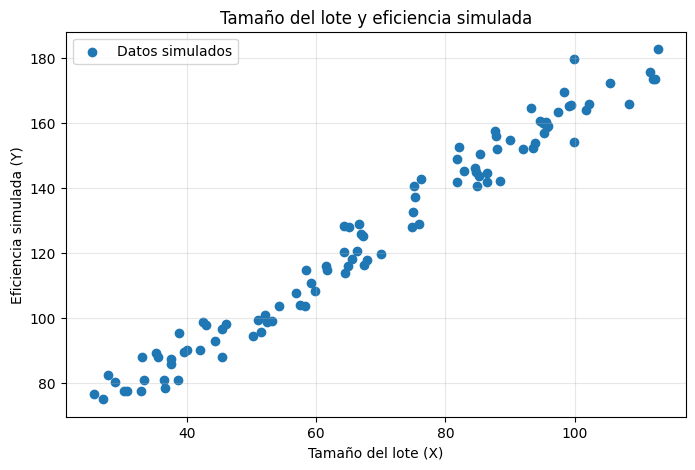

In [11]:
plt.figure(figsize=(8, 5))  # Define el tamaño de la gráfica.
plt.scatter(X[:, 0], y, label="Datos simulados")  # Dibuja las observaciones como puntos.
plt.title("Tamaño del lote y eficiencia simulada")  # Añade el título.
plt.xlabel("Tamaño del lote (X)")  # Etiqueta el eje horizontal.
plt.ylabel("Eficiencia simulada (Y)")  # Etiqueta el eje vertical.
plt.legend()  # Muestra la leyenda.
plt.grid(True, alpha=0.3)  # Añade una cuadrícula tenue.
plt.show()  # Presenta la gráfica.

## 7. Separar datos para ajuste y evaluación

Se reserva una parte de las observaciones para evaluar el modelo. El ajuste se realiza con el conjunto de entrenamiento.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42  # Reserva 20 % para evaluación y fija la partición.
)
print("Observaciones para ajuste:", len(X_train))  # Muestra cuántas filas se usarán para ajustar.
print("Observaciones para evaluación:", len(X_test))  # Muestra cuántas filas se reservaron.

Observaciones para ajuste: 80
Observaciones para evaluación: 20


## 8. Crear el pipeline y ajustar el polinomio de grado 5

El pipeline transforma X en potencias hasta \(x^5\) y después ajusta la regresión. El ajuste se realiza por mínimos cuadrados.

In [13]:
grado = 5  # Selecciona grado 5, que es mayor que 3 como pide la práctica.
modelo = Pipeline([
    ("polinomio", PolynomialFeatures(degree=grado, include_bias=False)),  # Genera x, x², x³, x⁴ y x⁵.
    ("regresion", LinearRegression())  # Estima los coeficientes por mínimos cuadrados.
])
modelo.fit(X_train, y_train)  # Ajusta el pipeline con los datos de entrenamiento.
print("Ajuste terminado con grado", grado)  # Confirma el grado usado.

Ajuste terminado con grado 5


## 9. Graficar la curva ajustada

Se calcula la predicción para valores ordenados de X y se dibuja la curva junto con las observaciones.

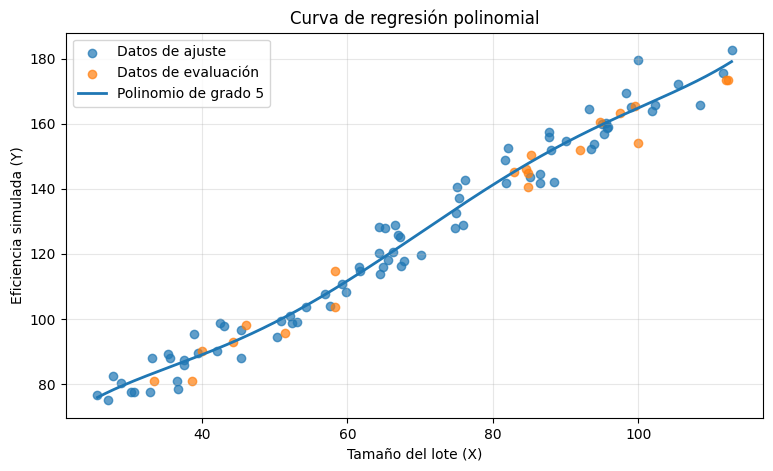

In [14]:
X_curva = np.linspace(X.min(), X.max(), 400).reshape(-1, 1)  # Crea valores ordenados para dibujar una curva suave.
y_curva = modelo.predict(X_curva)  # Calcula la respuesta predicha para cada valor de X.
plt.figure(figsize=(9, 5))  # Define el tamaño de la gráfica.
plt.scatter(X_train[:, 0], y_train, label="Datos de ajuste", alpha=0.7)  # Muestra datos usados para ajustar.
plt.scatter(X_test[:, 0], y_test, label="Datos de evaluación", alpha=0.7)  # Muestra datos reservados.
plt.plot(X_curva[:, 0], y_curva, label="Polinomio de grado 5", linewidth=2)  # Dibuja la curva estimada.
plt.title("Curva de regresión polinomial")  # Añade el título.
plt.xlabel("Tamaño del lote (X)")  # Etiqueta el eje X.
plt.ylabel("Eficiencia simulada (Y)")  # Etiqueta el eje Y.
plt.legend()  # Muestra la leyenda.
plt.grid(True, alpha=0.3)  # Añade una cuadrícula tenue.
plt.show()  # Presenta la gráfica.

## 10. Evaluación del ajuste mediante R²

La página define \(R^2\) como la proporción de variación de Y explicada por el modelo. Un valor más alto suele indicar un mejor ajuste, pero no demuestra por sí solo que el modelo sea adecuado. Por eso también se revisan los residuos.

\[
R^2=1-\frac{SS_{error}}{SS_{total}}
\]

In [15]:
y_pred = modelo.predict(X_test)  # Predice Y para las observaciones reservadas.
r2 = r2_score(y_test, y_pred)  # Compara las predicciones con los valores observados.
print(f"R² en los datos de evaluación: {r2:.4f}")  # Muestra R² con cuatro decimales.

R² en los datos de evaluación: 0.9801


## 11. Revisar los residuos

Los residuos son las diferencias entre los valores observados y los predichos. Según la página de referencia, deben revisarse estas condiciones:
- independencia;
- distribución aproximadamente normal, con media 0;
- varianza constante.

Una gráfica de residuos puede ayudar a detectar patrones o tendencias.

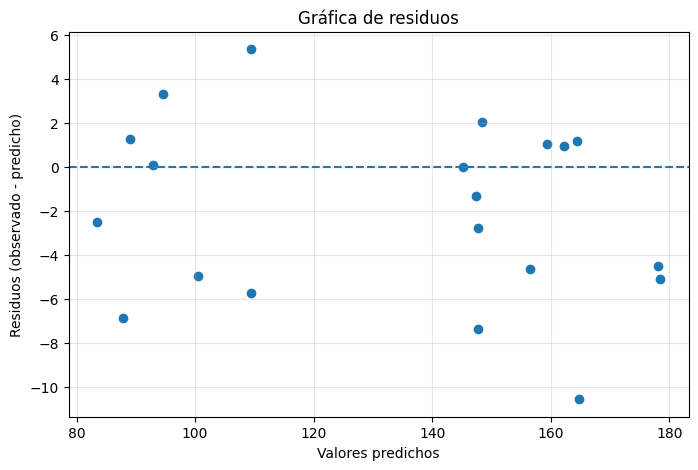

In [16]:
residuos = y_test - y_pred  # Calcula observado menos predicho para cada dato de evaluación.
plt.figure(figsize=(8, 5))  # Define el tamaño de la gráfica.
plt.scatter(y_pred, residuos)  # Grafica residuos frente a valores predichos.
plt.axhline(y=0, linestyle="--")  # Dibuja la línea de referencia en residuo cero.
plt.title("Gráfica de residuos")  # Añade el título.
plt.xlabel("Valores predichos")  # Etiqueta el eje horizontal.
plt.ylabel("Residuos (observado - predicho)")  # Etiqueta el eje vertical.
plt.grid(True, alpha=0.3)  # Añade una cuadrícula tenue.
plt.show()  # Presenta la gráfica.

## 12. Rango de inferencia y conclusión

La página advierte que la ecuación de regresión debe utilizarse dentro del rango de X observado; predecir fuera de ese rango puede producir resultados poco fiables. En el ejemplo de referencia, ese rango es de 25 a 115.

En este tutorial, los datos son simulados dentro de ese mismo rango para ilustrar el proceso. El valor de R² debe interpretarse junto con la gráfica de residuos: un R² alto no garantiza por sí solo un modelo adecuado.

**Conclusión:** se implementó una regresión polinomial de grado 5 mediante un pipeline de Scikit-learn. El modelo ajusta los coeficientes por mínimos cuadrados, se representa mediante una curva y se evalúa con R² y la revisión de residuos.

## Referencia

Six Sigma Material. *Linear, Non-Linear, and Multiple Regression*.  
https://www.six-sigma-material.com/Regression.html